# 5. Light-Sheet smFRET Camera Simulation

This notebook simulates camera frames of fluorescence emission from freely diffusing particles, as observed with a light-sheet microscope.

The light-sheet PSF is computed with the [`psfmodels`](https://github.com/scottptt/psfmodels) module and wrapped in the class `LightSheetPSF` (`lightsheet_psf.py`), which implements the pybromo PSF interface (`eval`, `eval_xz`, `hash`, `to_hdf5`). The effective PSF is the product of:

1. **Excitation**: a Gaussian light sheet, thin in z (sheet NA 0.08 → 1/e² thickness ≈ 2 µm), uniform in x/y
2. **Detection**: the vectorial widefield PSF of the detection objective (Gibson–Lanni model via `psfmodels.make_psf`)

The particle trajectories are simulated with pybromo (notebook 1) with camera-like parameters:

- **Simulation time**: 100 s
- **Simulation step**: 1 ms (pybromo `t_step`)
- **Camera frame integration time**: 50 ms (50 simulation steps per frame)

Camera frames are generated by weighting each particle's emission with the light-sheet excitation profile at its z position, binning the expected photon counts on the camera pixel grid and convolving with the detection PSF on the focal plane. Shot noise is applied by Poisson sampling.

In [1]:
%matplotlib inline
import numpy as np
import tables
import matplotlib.pyplot as plt
import seaborn as sns
import pybromo as pbm
import psfmodels
from lightsheet_psf import LightSheetPSF

print('Numpy version:', np.__version__)
print('PyTables version:', tables.__version__)
print('PyBroMo version:', pbm.__version__)
print('psfmodels version:', psfmodels.__version__)

/workspace/github__Tomkaehst__PyBroMo/pybromo/psflib.py:15: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Numpy version: 2.5.4
PyTables version: 3.11.1
PyBroMo version: 0+untagged.1.g5fecc87
psfmodels version: 0.3.3


## Light-Sheet PSF

The `LightSheetPSF` builds the effective (excitation × detection) PSF on a 3D grid with `psfmodels`:

- `dxy = 0.2 µm`: lateral grid step — matched to the camera pixel size in sample space
- `nx = 51`: lateral grid size
- `dz = 0.25 µm`, `nz_half = 24`: z grid spanning ±6 µm around focus
- `det_NA = 0.8`, `em_wvl = 0.58 µm`: detection objective
- `ex_wvl = 0.488 µm`, `sheet_NA = 0.08`: light-sheet excitation

In [2]:
ls_psf = LightSheetPSF(dxy=0.2, nx=51, dz=0.25, nz_half=24,
                        det_NA=0.8, em_wvl=0.58,
                        ex_wvl=0.488, sheet_NA=0.08)
print(ls_psf)
print('Sheet 1/e^2 waist: %.2f um' % ls_psf.sheet_waist)
print('PSF volume:', ls_psf.psf_volume.shape)
print('PSF hash:', ls_psf.hash()[:12])

LightSheetPSF(dxy=0.2um, nx=51, dz=0.25um, nz_half=24, det_NA=0.8, em_wvl=0.58um, ex_wvl=0.488um, sheet_NA=0.08)
Sheet 1/e^2 waist: 1.94 um
PSF volume: (49, 51, 51)
PSF hash: 2e7ea8185848


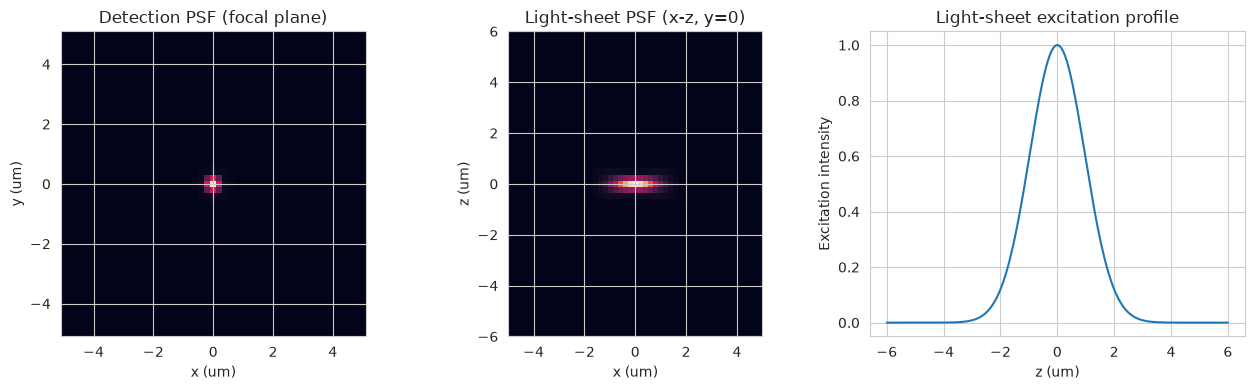

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# Focal-plane (detection) PSF
axes[0].imshow(ls_psf.focal_plane_psf, extent=[-5.1, 5.1, -5.1, 5.1])
axes[0].set_title('Detection PSF (focal plane)')
axes[0].set_xlabel('x (um)'); axes[0].set_ylabel('y (um)')

# X-Z slice of the effective light-sheet PSF (y = 0)
xz = ls_psf.eval_xz(*np.meshgrid(np.linspace(-5e-6, 5e-6, 51),
                                 np.linspace(-6e-6, 6e-6, 49))[::-1])
im = axes[1].imshow(xz, extent=[-5, 5, -6, 6], origin='lower')
axes[1].set_title('Light-sheet PSF (x-z, y=0)')
axes[1].set_xlabel('x (um)'); axes[1].set_ylabel('z (um)')

# Light-sheet excitation profile
z_um = np.linspace(-6, 6, 200)
axes[2].plot(z_um, ls_psf.excitation_weights(z_um * 1e-6))
axes[2].set_title('Light-sheet excitation profile')
axes[2].set_xlabel('z (um)'); axes[2].set_ylabel('Excitation intensity')
plt.tight_layout();

## Particle Trajectory Simulation (pybromo)

Camera-system simulation parameters:

| Parameter | Value |
|---|---|
| Simulation duration | 100 s |
| Simulation time step | 1 ms |
| Camera frame integration time | 50 ms |
| Diffusion coefficient | 10 µm²/s |
| Particles | 15 |
| Simulation box | 25.6 × 25.6 × 16 µm³ |

The simulation box matches a 128 × 128 pixel camera ROI at 0.2 µm/pixel (sample space). Positions are stored (`save_pos=True`) for the camera-frame rendering; the pybromo per-particle emission uses the light-sheet PSF.

In [4]:
rs = np.random.RandomState()
print('Initial random state:', pbm.hashfunc(rs.get_state()))

# Camera system parameters
t_step = 1e-3        # simulation step: 1 ms
t_max = 100          # total simulated time: 100 s
frame_steps = 50     # camera frame integration: 50 steps = 50 ms
frame_time = frame_steps * t_step
pixel_size = 0.2e-6  # camera pixel size in sample space (m)
roi = 128            # camera ROI in pixels

n_frames = int(t_max / frame_time)
print(f'Number of camera frames: {n_frames}')

# Simulation box: matched to the camera ROI
box = pbm.Box(x1=-roi/2*pixel_size, x2=roi/2*pixel_size,
              y1=-roi/2*pixel_size, y2=roi/2*pixel_size,
              z1=-8e-6, z2=8e-6)

# Particles definition
Du = 10.0            # um^2 / s
D1 = Du*(1e-6)**2    # m^2 / s
n_particles = 15
P = pbm.Particles.from_specs(
    num_particles=(n_particles,),
    D=(D1,),
    box=box, rs=rs)

# PSF: the light-sheet PSF (pybromo-compatible)
S = pbm.ParticlesSimulation(t_step=t_step, t_max=t_max,
                            particles=P, box=box, psf=ls_psf)
print('Current random state:', pbm.hashfunc(rs.get_state()))
print(S)
S.print_sizes()

Initial random state: 6d0bd6d06d7502255c31be7c712cd641d342f5ff
Number of camera frames: 2000
Current random state: 0bc6870d7d6795a07bda622071cdbc2501040742
Box: X 25.6um, Y 25.6um, Z 16.0um
#Particles: 15 D: 1e-11, 2.4 pM, t_step 1000.0us, t_max 100.0s ID_EID 0 0
  Number of particles: 15
  Number of time steps: 100000
  Emission array - 1 particle (float32): 0.4 MB
  Emission array (float32): 5.7 MB
  Position array (float32): 17.2 MB 


In [5]:
S.simulate_diffusion(
    total_emission=False,
    save_pos=True,
    verbose=True,
    rs=rs,
    chunksize=2**20,
    chunkslice='times'
)

- Start trajectories simulation - Tue Oct 27 21:55:47 2026


[PID 1302] Diffusion time: 1048s


- End trajectories simulation - Tue Oct 27 21:55:48 2026


## Camera Frames from PSF Convolution

The stored particle positions `(num_particles, 3, n_samples)` are rendered into camera frames:

1. **Excitation weighting**: each particle's emission is modulated by the light-sheet excitation profile at its z position (particles outside the sheet go dark)
2. **Pixel binning**: expected photon counts are binned onto the camera pixel grid (128 × 128 at 0.2 µm/pixel)
3. **PSF convolution**: the 2D image is convolved with the detection PSF on the focal plane (`LightSheetPSF.focal_plane_psf`, sum-normalized), spreading each particle's counts over a diffraction-limited spot
4. **Shot noise**: Poisson sampling of the expected image yields integer photon counts per pixel

Emission rate: 50 kcps per particle at the sheet center; camera background: 10 cps/pixel.

In [6]:
positions = S.position[:]   # (num_particles, 3, n_samples)
print('Positions array:', positions.shape)
print('Samples:', positions.shape[-1], '-> frames:', positions.shape[-1] // frame_steps)

em_rate = 50e3        # photons/s per particle at the sheet center
background_rate = 10  # photons/s/pixel

frames = ls_psf.render_camera_frames(
    positions,
    t_step=t_step,
    frame_steps=frame_steps,
    em_rate=em_rate,
    roi=roi,
    pixel_size_m=pixel_size,
    background_rate=background_rate,
    rs=rs)
print('Camera frames:', frames.shape, frames.dtype)
print('Photons per frame (mean):', frames.sum(axis=(1, 2)).mean().round(1))

Positions array: (15, 3, 100000)
Samples: 100000 -> frames: 2000


Camera frames: (2000, 128, 128) uint16
Photons per frame (mean): 13960.2


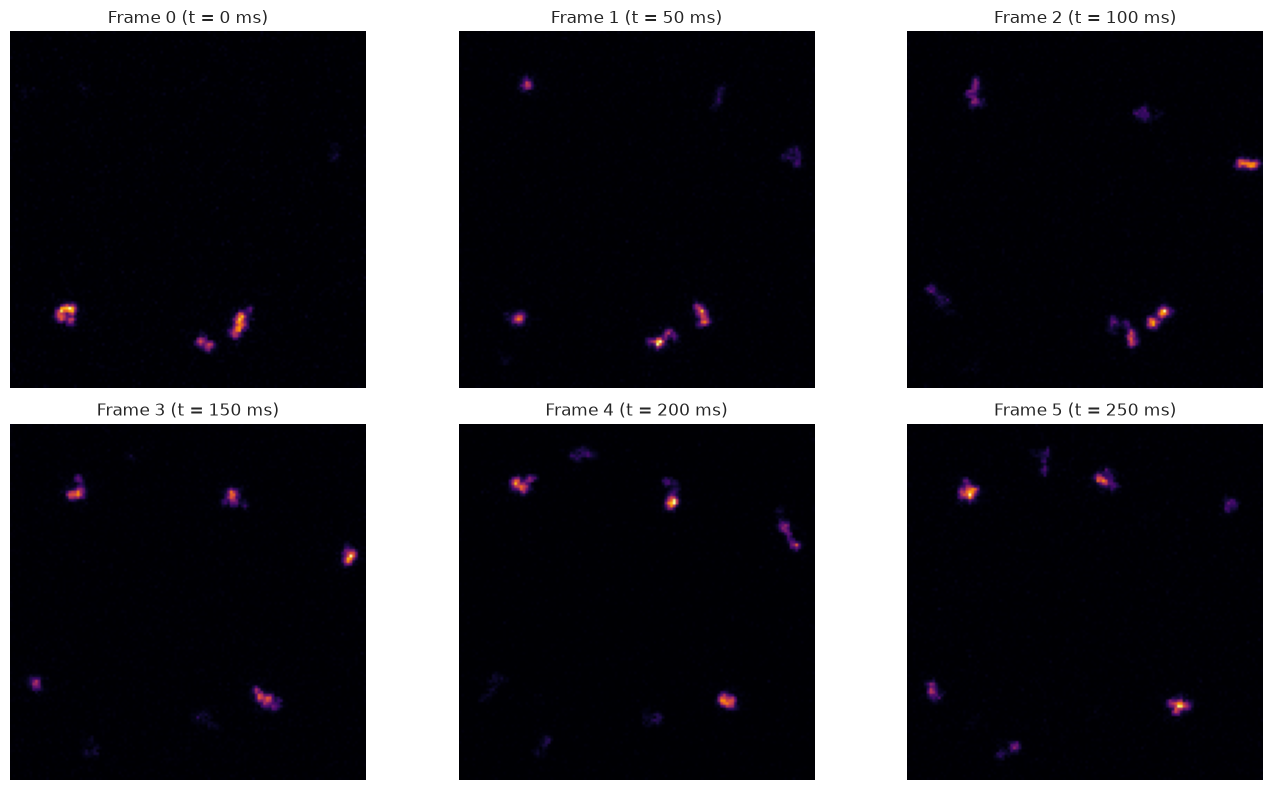

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(frames[i], cmap='inferno')
    ax.set_title(f'Frame {i} (t = {i*frame_time*1e3:.0f} ms)')
    ax.set_axis_off()
plt.tight_layout();

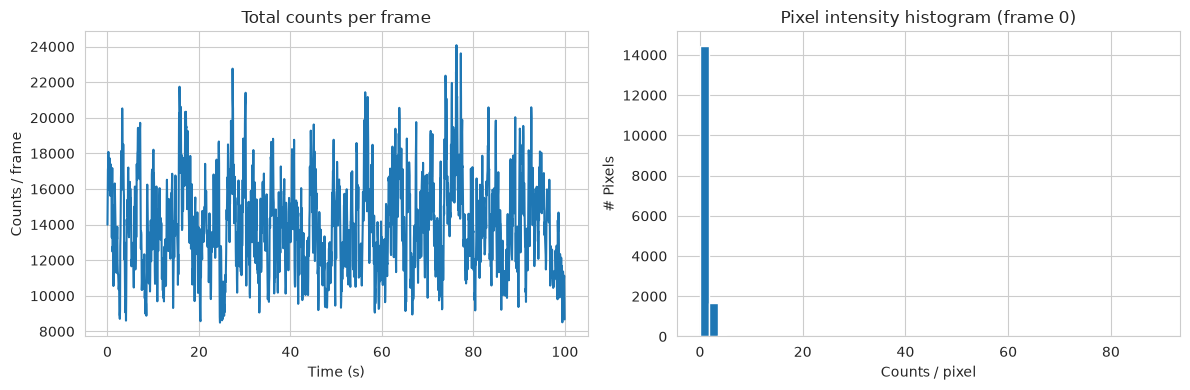

In [8]:
# Intensity trace and spot dynamics
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t_frames = np.arange(frames.shape[0]) * frame_time
axes[0].plot(t_frames, frames.sum(axis=(1, 2)))
axes[0].set_xlabel('Time (s)'); axes[0].set_ylabel('Counts / frame')
axes[0].set_title('Total counts per frame')

f_max = frames[0].max()
axes[1].hist(frames[0].ravel(), bins=50, range=(0, f_max))
axes[1].set_xlabel('Counts / pixel'); axes[1].set_ylabel('# Pixels')
axes[1].set_title('Pixel intensity histogram (frame 0)')
plt.tight_layout();

## Saving the Camera Frames

The camera frame stack is saved as an HDF5 file, alongside the pybromo trajectory file. The pybromo trajectory file already contains the light-sheet PSF (via `LightSheetPSF.to_hdf5`), so the simulation is fully traceable.

In [9]:
sim_name = S.compact_name()
S.store.close()

filename = f'lightsheet_camera_{sim_name}.hdf5'
with tables.open_file(filename, 'w') as f:
    f.create_array('/', 'frames', obj=frames,
                   title='Simulated light-sheet camera frames (uint16)')
    for attr, value in [('frame_time', frame_time),
                        ('t_step', t_step),
                        ('pixel_size_m', pixel_size),
                        ('em_rate', em_rate),
                        ('background_rate', background_rate),
                        ('psf_hash', ls_psf.hash())]:
        f.set_node_attr(f.root, attr, value)
print('Saved:', filename)

Saved: lightsheet_camera_6c1591_P15_D1e-11_2pM_step1000.0us_t_max100.0s_ID0-0.hdf5


## Summary

- `lightsheet_psf.py` provides `LightSheetPSF`, a pybromo-compatible light-sheet PSF computed with the `psfmodels` vectorial model (widefield detection) multiplied by a Gaussian light-sheet excitation profile
- The pybromo particle simulation runs with camera-system parameters: 100 s duration, 1 ms step, 50 ms camera frame integration
- `LightSheetPSF.render_camera_frames` convolves the particle emission field with the light-sheet detection PSF and applies Poisson shot noise, producing uint16 camera frames (2000 frames of 128 × 128 pixels for this simulation)